# Visualize data splits on the plate map

We show which wells are held out and how single cells from the remaining wells are split into training and testing data.

- **Held out wells** are filled with one color (whole held out biological replicate or one held out well per treatment per remaining biological replicate).
- **Training and testing wells** are pie charts, because we split single cells (not wells) 70/30 into training and testing data. The pie shows the fraction of cells per well in the training data (after downsampling), removed by downsampling, and in the testing data.
- A bar plot shows the number of cells per biological replicate, treatment, and data split.

In [1]:
suppressPackageStartupMessages({
    library(dplyr)
    library(tidyr)
    library(ggplot2)
    library(arrow)
    library(patchwork)
})

Warning message:
“package ‘tidyr’ was built under R version 4.2.3”


Warning message:
“package ‘ggplot2’ was built under R version 4.2.3”


Warning message:
“package ‘arrow’ was built under R version 4.2.3”


Warning message:
“package ‘patchwork’ was built under R version 4.2.3”


## Set paths and variables

In [2]:
# Directory with the data splits
split_dir <- file.path("data_splits", "model_TGFB_vs_Veh")

# Plate map
platemap_file <- file.path("..", "metadata", "platemaps", "pilot_platemap.csv")

# Output directories
output_fig_dir <- file.path("figures")
summary_dir <- file.path("data_split_summary")
for (d in c(output_fig_dir, summary_dir)) {
    if (!dir.exists(d)) dir.create(d, recursive = TRUE)
}

# Data split order and colors (same as the model performance figures, distinct from the treatment colors)
split_levels <- c(
    "Training",
    "Removed by downsampling",
    "Testing",
    "Holdout: whole replicate",
    "Holdout: one well per treatment"
)
split_colors <- c(
    "Training" = "#6250d6",
    "Removed by downsampling" = "#c9c9c6",
    "Testing" = "#e87ba4",
    "Holdout: whole replicate" = "#1baf7a",
    "Holdout: one well per treatment" = "#eda100"
)

## Count cells per well per data split

In [3]:
# Count cells per well in a data split file
count_cells <- function(file_name, name) {
    read_parquet(file.path(split_dir, file_name), col_select = "Metadata_Well") %>%
        count(Metadata_Well, name = name)
}

holdout_counts <- read_parquet(
    file.path(split_dir, "holdout_split.parquet"),
    col_select = c("Metadata_Well", "Metadata_holdout_type")
) %>%
    count(Metadata_Well, Metadata_holdout_type, name = "n_holdout")

platemap_df <- readr::read_csv(platemap_file, col_types = readr::cols(.default = "c"))

counts_df <- platemap_df %>%
    select(well_position, WellRow, WellCol, Treatment, N_Replicate) %>%
    left_join(count_cells("training_split.parquet", "n_training_split"), by = c("well_position" = "Metadata_Well")) %>%
    left_join(count_cells("downsample_training_split.parquet", "Training"), by = c("well_position" = "Metadata_Well")) %>%
    left_join(count_cells("testing_split.parquet", "Testing"), by = c("well_position" = "Metadata_Well")) %>%
    left_join(holdout_counts, by = c("well_position" = "Metadata_Well")) %>%
    mutate(across(c(n_training_split, Training, Testing, n_holdout), ~ replace_na(.x, 0L))) %>%
    mutate(
        `Removed by downsampling` = n_training_split - Training,
        `Holdout: whole replicate` = ifelse(Metadata_holdout_type %in% "replicate", n_holdout, 0L),
        `Holdout: one well per treatment` = ifelse(Metadata_holdout_type %in% "well", n_holdout, 0L)
    ) %>%
    select(-n_training_split, -n_holdout, -Metadata_holdout_type)

# Save cell counts per well and data split
readr::write_csv(counts_df, file.path(summary_dir, "cells_per_well_per_split.csv"))

# Total cells per data split
colSums(counts_df[, split_levels])
head(counts_df)

Training         Removed by downsampling 
                           4786                             361 
                        Testing        Holdout: whole replicate 
                           2207                            2598 
Holdout: one well per treatment 
                           1671

well_position,WellRow,WellCol,Treatment,N_Replicate,Training,Testing,Removed by downsampling,Holdout: whole replicate,Holdout: one well per treatment
<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<int>,<int>,<int>,<int>
B03,B,3,TGFB,N2,182,69,0,0,0
B04,B,4,Veh,N3,0,0,0,289,0
B05,B,5,TGFB,N1,186,67,0,0,0
B06,B,6,TGFB,N4,0,0,0,0,300
B07,B,7,TGFB,N1,0,0,0,0,327
B08,B,8,Veh,N1,161,67,23,0,0


## Create pie chart polygons per well

In [4]:
# Long format with the fraction of cells per data split per well
long_df <- counts_df %>%
    pivot_longer(cols = all_of(split_levels), names_to = "split", values_to = "n_cells") %>%
    filter(n_cells > 0) %>%
    mutate(split = factor(split, levels = split_levels)) %>%
    arrange(well_position, split) %>%
    group_by(well_position) %>%
    mutate(
        frac = n_cells / sum(n_cells),
        end = cumsum(frac),
        start = end - frac
    ) %>%
    ungroup() %>%
    mutate(
        x = as.integer(WellCol),
        y = 9 - match(WellRow, LETTERS),
        wedge_id = row_number()
    )

# Polygon for one pie wedge (clockwise from 12 o'clock); a full circle if the wedge is the whole well
radius <- 0.44
make_wedge <- function(x0, y0, start, end, id, split) {
    n_points <- max(3, ceiling(120 * (end - start)))
    theta <- seq(start, end, length.out = n_points) * 2 * pi
    xs <- x0 + radius * sin(theta)
    ys <- y0 + radius * cos(theta)
    if (end - start < 0.9999) {
        xs <- c(x0, xs)
        ys <- c(y0, ys)
    }
    data.frame(x = xs, y = ys, wedge_id = id, split = split)
}

wedge_df <- bind_rows(lapply(seq_len(nrow(long_df)), function(i) {
    r <- long_df[i, ]
    make_wedge(r$x, r$y, r$start, r$end, r$wedge_id, as.character(r$split))
})) %>%
    mutate(split = factor(split, levels = split_levels))

# Circle outlines for used and empty wells
make_circle <- function(x0, y0, id) {
    theta <- seq(0, 2 * pi, length.out = 120)
    data.frame(x = x0 + radius * sin(theta), y = y0 + radius * cos(theta), well = id)
}
all_wells <- expand.grid(x = 1:12, y = 1:8)
all_wells$well <- seq_len(nrow(all_wells))
used <- paste(long_df$x, long_df$y) %>% unique()
all_wells$used <- paste(all_wells$x, all_wells$y) %in% used
circle_df <- bind_rows(lapply(seq_len(nrow(all_wells)), function(i) {
    make_circle(all_wells$x[i], all_wells$y[i], all_wells$well[i])
})) %>%
    left_join(all_wells[, c("well", "used")], by = "well")

# Labels per well (biological replicate and treatment)
label_df <- long_df %>%
    distinct(well_position, x, y, N_Replicate, Treatment) %>%
    mutate(label = paste0(N_Replicate, "\n", ifelse(Treatment == "TGFB", "TGF-β", "Veh")))

## Plot plate map and cell counts

Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'TGF-β' in 'mbcsToSbcs': dot substituted for <ce>”


Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'TGF-β' in 'mbcsToSbcs': dot substituted for <b2>”


Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'TGF-β' in 'mbcsToSbcs': dot substituted for <ce>”


Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'TGF-β' in 'mbcsToSbcs': dot substituted for <b2>”


Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'TGF-β' in 'mbcsToSbcs': dot substituted for <ce>”


Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'TGF-β' in 'mbcsToSbcs': dot substituted for <b2>”


... (260 outputs left out)

Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'TGF-β' in 'mbcsToSbcs': dot substituted for <ce>”


Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'TGF-β' in 'mbcsToSbcs': dot substituted for <b2>”


Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'TGF-β' in 'mbcsToSbcs': dot substituted for <ce>”


Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'TGF-β' in 'mbcsToSbcs': dot substituted for <b2>”


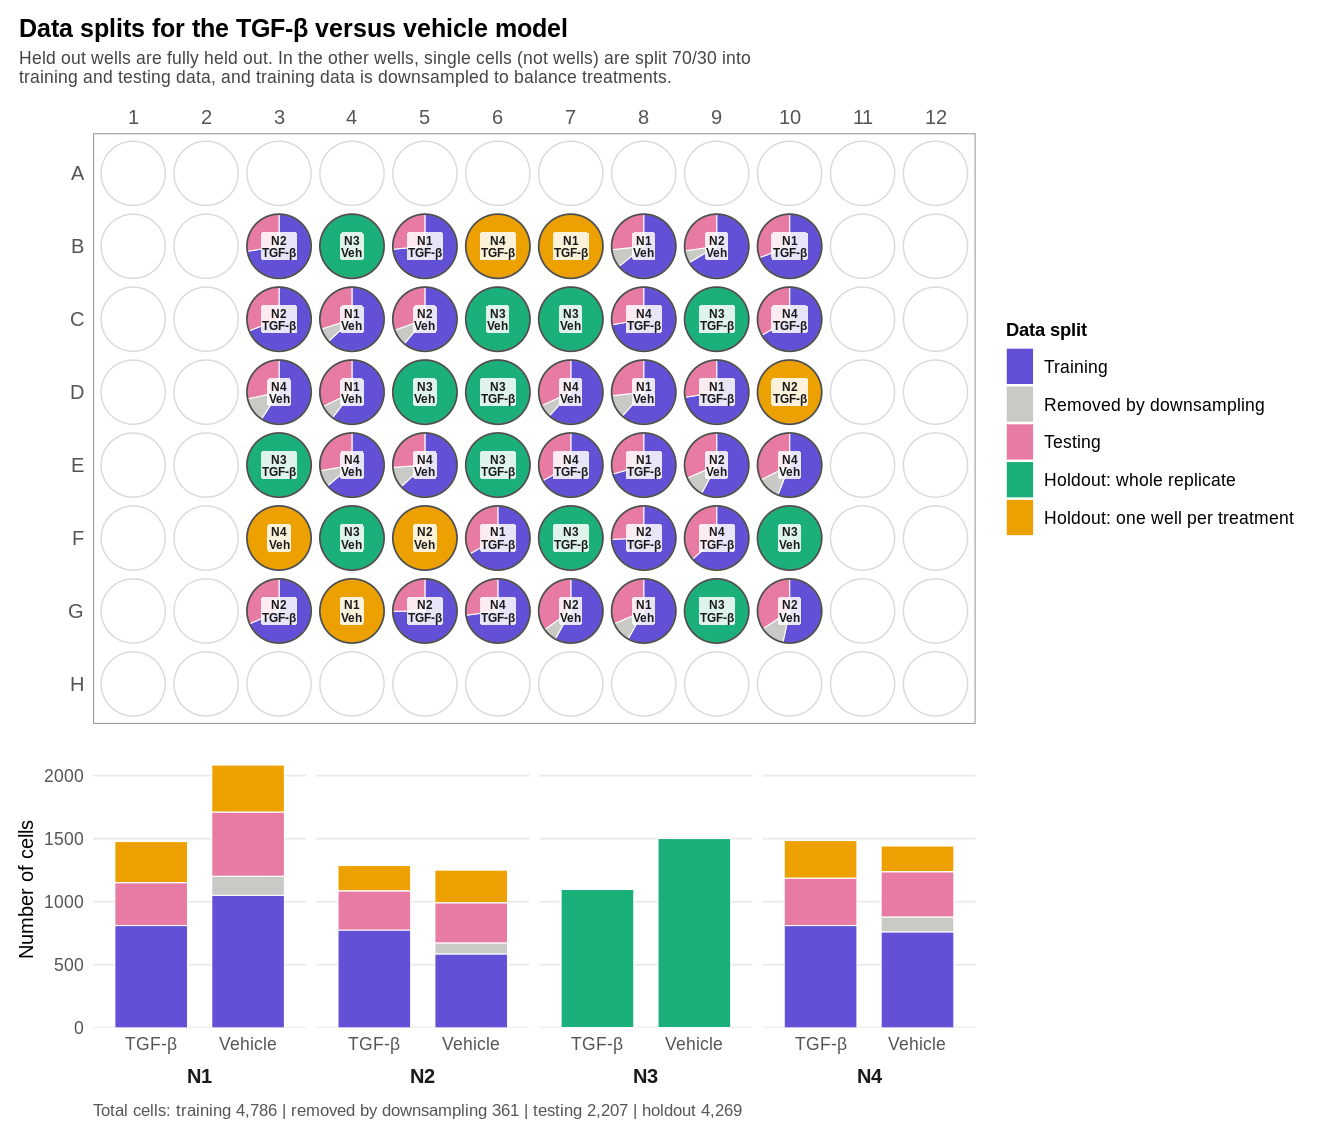

In [5]:
totals <- colSums(counts_df[, split_levels])

platemap_gg <- ggplot() +
    geom_polygon(
        data = filter(circle_df, !used), aes(x = x, y = y, group = well),
        fill = NA, color = "#d9d9d6", linewidth = 0.4
    ) +
    geom_polygon(
        data = wedge_df, aes(x = x, y = y, group = wedge_id, fill = split),
        color = "white", linewidth = 0.3
    ) +
    geom_polygon(
        data = filter(circle_df, used), aes(x = x, y = y, group = well),
        fill = NA, color = "#4d4d4b", linewidth = 0.5
    ) +
    geom_label(
        data = label_df, aes(x = x, y = y, label = label),
        color = "#1a1a1a", fill = "white", alpha = 0.85, fontface = "bold", size = 2.5,
        lineheight = 0.85, label.size = 0, label.padding = unit(0.08, "lines")
    ) +
    scale_fill_manual(name = "Data split", values = split_colors, drop = FALSE) +
    scale_x_continuous(breaks = 1:12, position = "top", limits = c(0.45, 12.55), expand = c(0, 0)) +
    scale_y_continuous(breaks = 1:8, labels = rev(LETTERS[1:8]), limits = c(0.45, 8.55), expand = c(0, 0)) +
    coord_fixed() +
    labs(
        title = "Data splits for the TGF-β versus vehicle model",
        subtitle = paste0(
            "Held out wells are fully held out. In the other wells, single cells (not wells) are split 70/30 into\n",
            "training and testing data, and training data is downsampled to balance treatments."
        ),
        x = NULL, y = NULL
    ) +
    theme_minimal(base_size = 12) +
    theme(
        plot.title = element_text(size = 15, face = "bold"),
        plot.subtitle = element_text(size = 10.5, color = "#444444"),
        plot.title.position = "plot",
        panel.grid = element_blank(),
        panel.border = element_rect(color = "#999999", fill = NA, linewidth = 0.6),
        axis.text = element_text(size = 12, color = "#555555"),
        legend.title = element_text(size = 11, face = "bold"),
        legend.text = element_text(size = 10.5),
        legend.key.height = unit(0.8, "cm")
    )

# Cells per biological replicate, treatment, and data split
bar_df <- counts_df %>%
    pivot_longer(cols = all_of(split_levels), names_to = "split", values_to = "n_cells") %>%
    group_by(N_Replicate, Treatment, split) %>%
    summarize(n_cells = sum(n_cells), .groups = "drop") %>%
    mutate(
        split = factor(split, levels = rev(split_levels)),
        Treatment = ifelse(Treatment == "TGFB", "TGF-β", "Vehicle")
    )

bar_gg <- ggplot(bar_df, aes(x = Treatment, y = n_cells, fill = split)) +
    geom_col(width = 0.75, color = "white", linewidth = 0.3) +
    facet_grid(. ~ N_Replicate, switch = "x") +
    scale_fill_manual(values = split_colors, guide = "none") +
    scale_y_continuous(expand = expansion(mult = c(0, 0.05))) +
    labs(
        x = NULL, y = "Number of cells",
        caption = paste0(
            "Total cells: training ", format(totals[["Training"]], big.mark = ","),
            " | removed by downsampling ", format(totals[["Removed by downsampling"]], big.mark = ","),
            " | testing ", format(totals[["Testing"]], big.mark = ","),
            " | holdout ", format(totals[["Holdout: whole replicate"]] + totals[["Holdout: one well per treatment"]], big.mark = ",")
        )
    ) +
    theme_minimal(base_size = 12) +
    theme(
        panel.grid.major.x = element_blank(),
        panel.grid.minor = element_blank(),
        strip.placement = "outside",
        strip.text = element_text(size = 12, face = "bold"),
        axis.text = element_text(size = 10.5, color = "#555555"),
        plot.caption = element_text(size = 10, color = "#555555", hjust = 0)
    )

width <- 11
height <- 9.5
options(repr.plot.width = width, repr.plot.height = height)

split_platemap_gg <- platemap_gg / bar_gg + plot_layout(heights = c(2.2, 1))

ggsave(file.path(output_fig_dir, "data_split_platemap.png"), split_platemap_gg, dpi = 500, width = width, height = height, bg = "white")
ggsave(file.path(output_fig_dir, "data_split_platemap.pdf"), split_platemap_gg, width = width, height = height, bg = "white")

split_platemap_gg